# Decoherence of neutrino oscillations with NeutrinoDecoherence.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/NeutrinoDecoherence.jl/blob/main/notebooks/01_decoherence.ipynb)

A neutrino is a superposition of propagation eigenstates. Oscillations come from the interference between them. If the neutrino interacts weakly with an environment (quantum gravity, fluctuating matter, …), this superposition slowly loses its phase information. In the Lindblad description the density matrix $\rho$ in the basis of propagation eigenstates evolves as

$$\rho_{ij}(L) = \rho_{ij}(0)\, e^{-i\Delta_{ij} L}\; e^{-\Gamma_{ij}\,(E/E_0)^n\, L}, \qquad i \neq j .$$

The off-diagonal terms decay while the populations $\rho_{ii}$ stay put. Oscillations wash out to their classical average, and the total probability is conserved.

NeutrinoDecoherence.jl adds this to [GLoBES.jl](https://github.com/JuliaNeutrino/GLoBES.jl) as a *propagation block*. Probabilities, event rates, χ² and fits in GLoBES.jl treat Γ like any other parameter, and the block combines with other blocks such as scalar NSI from [NeutrinoScalarNSI.jl](https://github.com/JuliaNeutrino/NeutrinoScalarNSI.jl).

In [ ]:
# Install GLoBES.jl, NeutrinoDecoherence.jl and NeutrinoScalarNSI.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/NeutrinoDecoherence.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/NeutrinoScalarNSI.jl")
Pkg.add("Plots")

In [1]:
using GLoBES, NeutrinoDecoherence, Plots
paper_theme!()   # Plots defaults for publication figures

## The whole package

`Decoherence` is a subtype of `GLoBES.PropagationBlock`. Unlike the NSI blocks, it leaves the Hamiltonian alone. It says that it `damps` and gives the three `damping_rates` (Γ21, Γ31, Γ32) at each energy. GLoBES.jl then propagates the density matrix layer by layer instead of the amplitude.

In [2]:
print(read(pathof(NeutrinoDecoherence), String))

"""
Environmental decoherence of neutrino oscillations for GLoBES.jl: damping
of the coherences between propagation eigenstates, as a propagation block
that combines with the other blocks in `NewPhysics`.
"""
module NeutrinoDecoherence

using GLoBES
using GLoBES: PropagationBlock
import GLoBES: block_parameters, parameter_aliases, damps, damping_rates

export Decoherence

"""
    Decoherence(; n=0, E0=1.0, pairs=false)

Environmental decoherence: the coherence between the propagation eigenstates
i, j (of the Hamiltonian in matter, numbered by increasing eigenvalue)
decays as exp(-Γ_ij (E/E₀)ⁿ L), with Γ in GeV and E and E₀ in GeV. One
parameter `Γ` for all pairs, or `Γ21`, `Γ31` and `Γ32` with `pairs = true`
(ASCII `Gamma`, `Gamma21`, ...).

The power n sets the energy dependence; n = 0, 2 and -1 are the usual
choices (Lisi, Marrone and Montanino, hep-ph/0002053).

```julia
Decoherence()   # one Γ for all pairs, independent of the energy
Decoherence(n = 2, pairs = true)   # Γ21, Γ31 an

One Γ for all three pairs, or one per pair with `pairs = true`. Γ is in GeV, and `n` and `E0` set the energy dependence $(E/E_0)^n$:

In [3]:
model = NewPhysics(Decoherence())
model, model.names, NewPhysics(Decoherence(n = 2, E0 = 10, pairs = true)).names

(NewPhysics(Decoherence(n = 0.0)), [:Γ], [:Γ21, :Γ31, :Γ32])

In [4]:
use_model!(model)   # the probability engine of everything in GLoBES.jl from now on
p = nufit_params("6.1")
sm = OscParams(model, p)
OscParams(model, p; Gamma = 1e-23) == OscParams(model, p; Γ = 1e-23)   # ASCII names work too

true

## Washing out the oscillations

How large is Γ = 10⁻²³ GeV? It is 10⁻¹⁴ eV, so the damping length 1/Γ is about 20 000 km, the size of the Earth. Here is ν_μ survival at 5 GeV in vacuum as a function of the distance, for three values of Γ. For large ΓL the probability settles at the classical value $\sum_i |U_{\mu i}|^4$, the average of the oscillation:

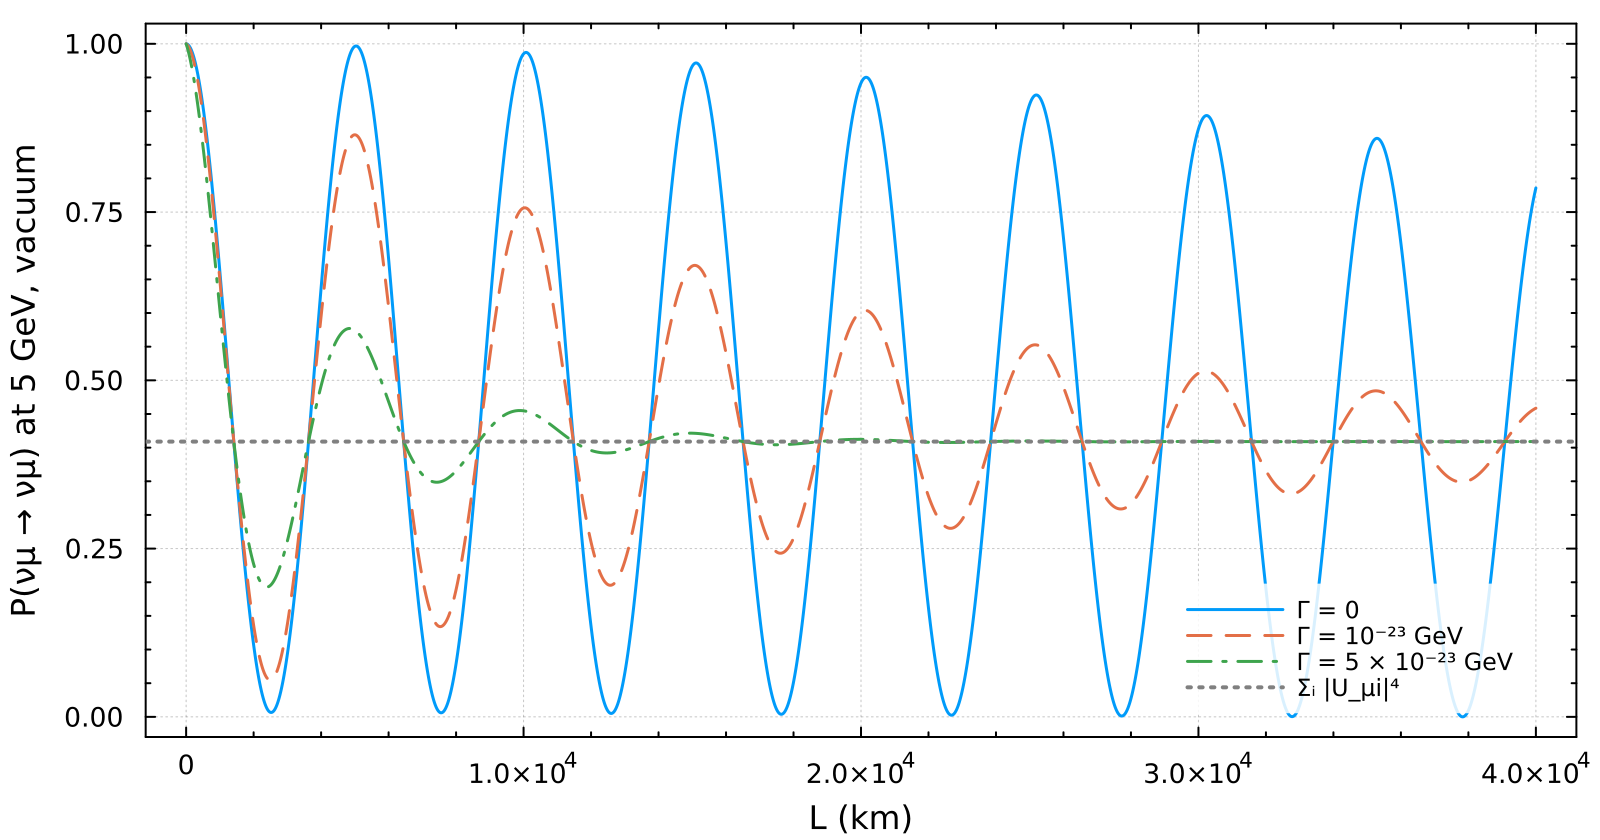

In [5]:
L = range(1, 40_000, 2000)
U = pmns_matrix(p)
classical = sum(abs2(U[2, i])^2 for i in 1:3)
plt = plot(; xlabel = "L (km)", ylabel = "P(νμ → νμ) at 5 GeV, vacuum", legend = :bottomright, size = (800, 420))
for (Γ, label, style) in ((0.0, "Γ = 0", :solid), (1e-23, "Γ = 10⁻²³ GeV", :dash), (5e-23, "Γ = 5 × 10⁻²³ GeV", :dashdot))
    q = OscParams(model, p; Γ)
    plot!(plt, L, [probability(q, :μ, :μ; E = [5.0], L = l, ρ = 0)[1] for l in L]; label, linestyle = style, linewidth = 1.5)
end
hline!(plt, [classical]; color = :gray, linestyle = :dot, label = "Σᵢ |U_μi|⁴")

Decoherence removes interference but never creates or destroys neutrinos, so the probabilities still sum to one:

In [6]:
q = OscParams(model, p; Γ = 3e-23)
sum(probability(q, :μ, β; E = [0.5, 1.0, 2.5, 5.0], L = 1300, ρ = 2.848) for β in (:e, :μ, :τ))

4-element Vector{Float64}:
 0.9999999999999999
 1.0000000000000007
 1.0000000000000004
 1.0000000000000009

## Appearance at DUNE

At 1300 km, Γ = 10⁻²³ GeV damps about 7% of the interference: e^(−ΓL) ≈ 0.93. The oscillation peaks fall and the troughs rise. This is unlike NSI, which shift the curve sideways or scale it.

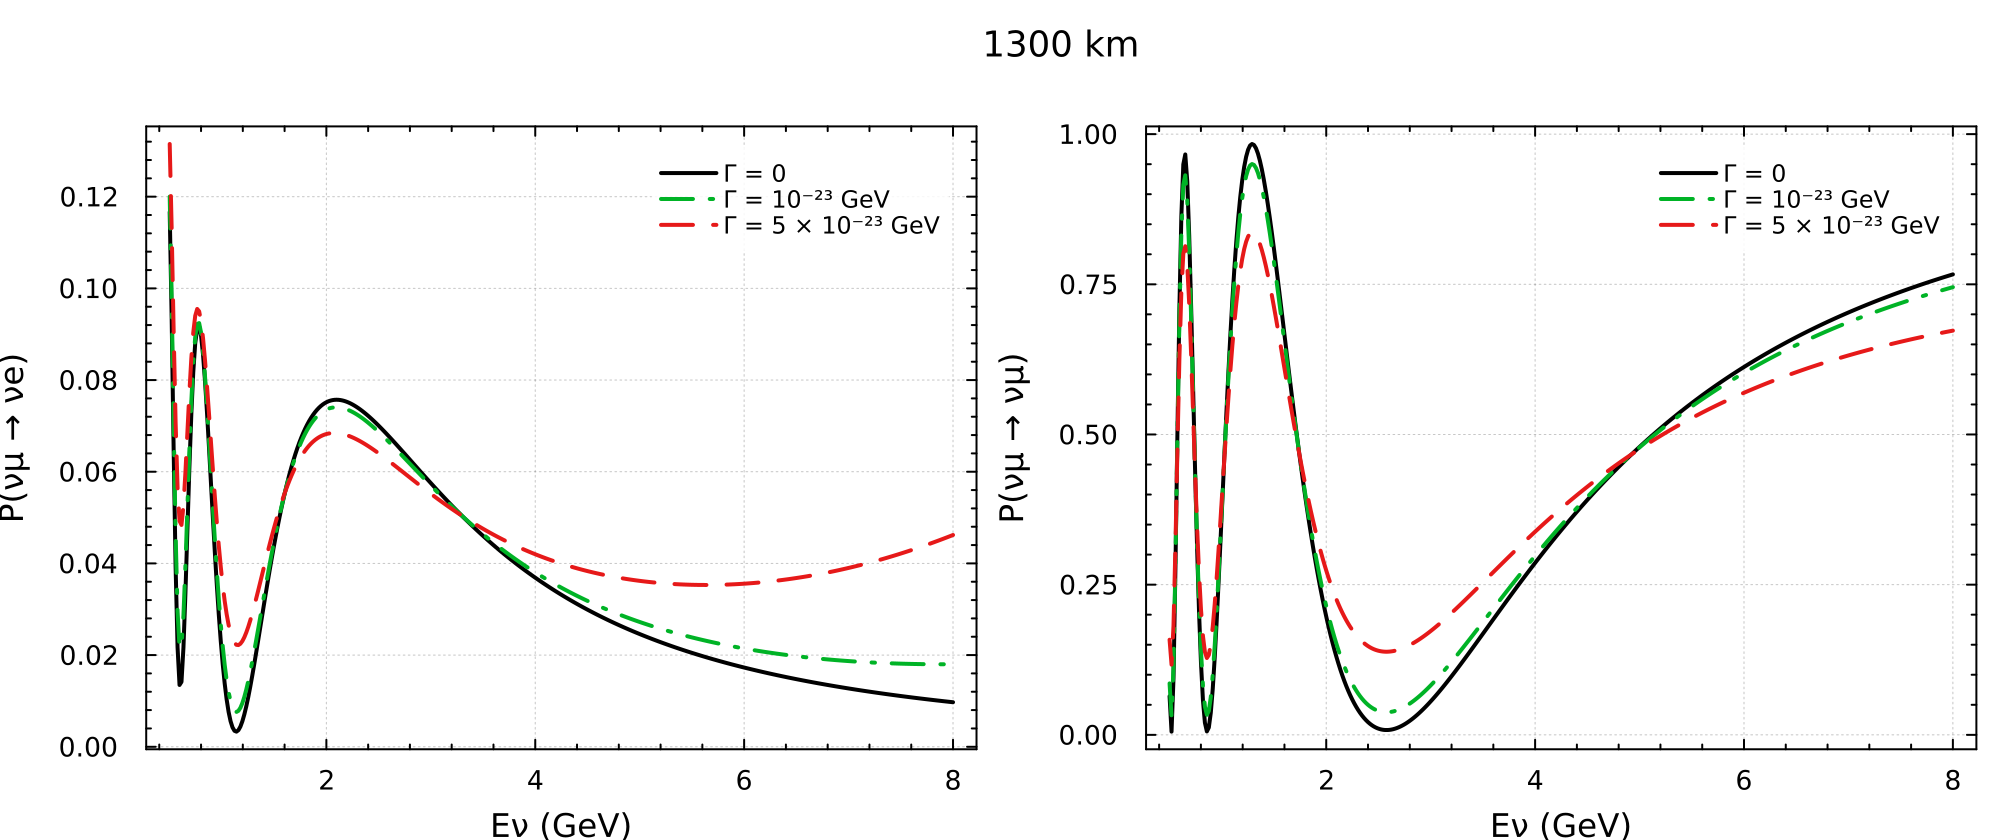

In [7]:
DUNE = (; L = 1300, ρ = 2.848)
E = range(0.5, 8, 400)
curves = ("Γ = 0" => sm, "Γ = 10⁻²³ GeV" => OscParams(model, p; Γ = 1e-23), "Γ = 5 × 10⁻²³ GeV" => OscParams(model, p; Γ = 5e-23))
panel(from, to) = plot_probability(curves...; from, to, E, DUNE...)
plot_grid([panel(:μ, :e) panel(:μ, :μ)]; title = "1300 km", size = (1000, 420))

## Which energies are damped: the power n

Models predict different energy dependences: n = 0 (constant), n = 2 (e.g. from space-time foam), n = −1 (energy-independent damping per oscillation phase, like a fluctuating Δm²). Here all three have Γ = 5 × 10⁻²³ GeV at E₀ = 2.5 GeV, near the DUNE peak:

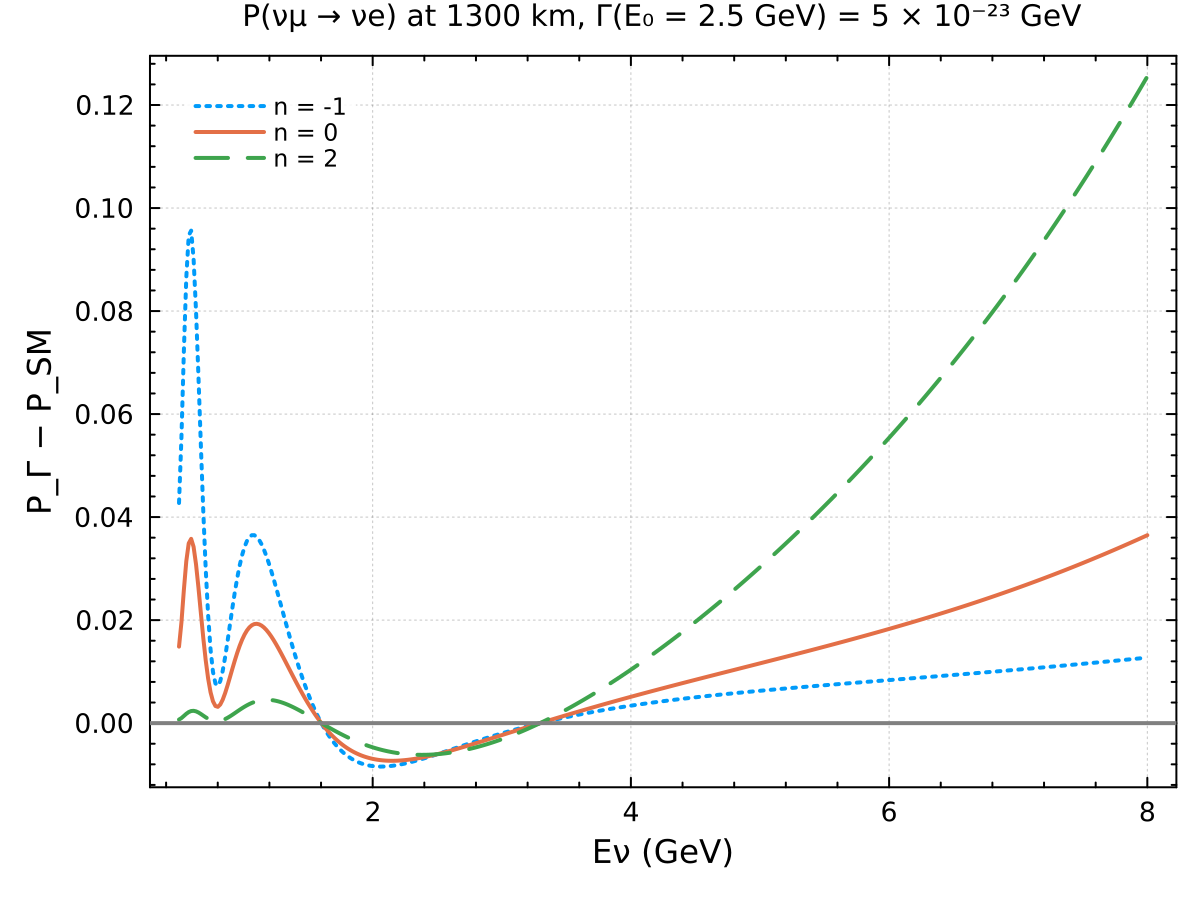

In [8]:
plt = plot(; xlabel = "Eν (GeV)", ylabel = "P_Γ − P_SM", title = "P(νμ → νe) at 1300 km, Γ(E₀ = 2.5 GeV) = 5 × 10⁻²³ GeV")
P_sm = probability(sm, :μ, :e; E = collect(E), DUNE...)
for (n, style) in ((-1, :dot), (0, :solid), (2, :dash))
    m = NewPhysics(Decoherence(; n, E0 = 2.5))
    use_model!(m)
    plot!(plt, E, probability(OscParams(m, p; Γ = 5e-23), :μ, :e; E = collect(E), DUNE...) .- P_sm; label = "n = $n", linestyle = style)
end
use_model!(model)
hline!(plt, [0]; color = :gray, label = "")

For n = 2 the damping is strongest at high energy, where DUNE's flux is falling. This is why high-energy atmospheric and astrophysical neutrinos are the best probes of positive n. For n = −1 the low-energy second oscillation maximum carries most of the effect.

## One rate per pair

With `pairs = true` each pair of eigenstates has its own rate. The eigenstates are those of the Hamiltonian in matter, numbered by increasing eigenvalue. The three rates damp different interference terms, so they are far from equivalent. The same value of each gives:

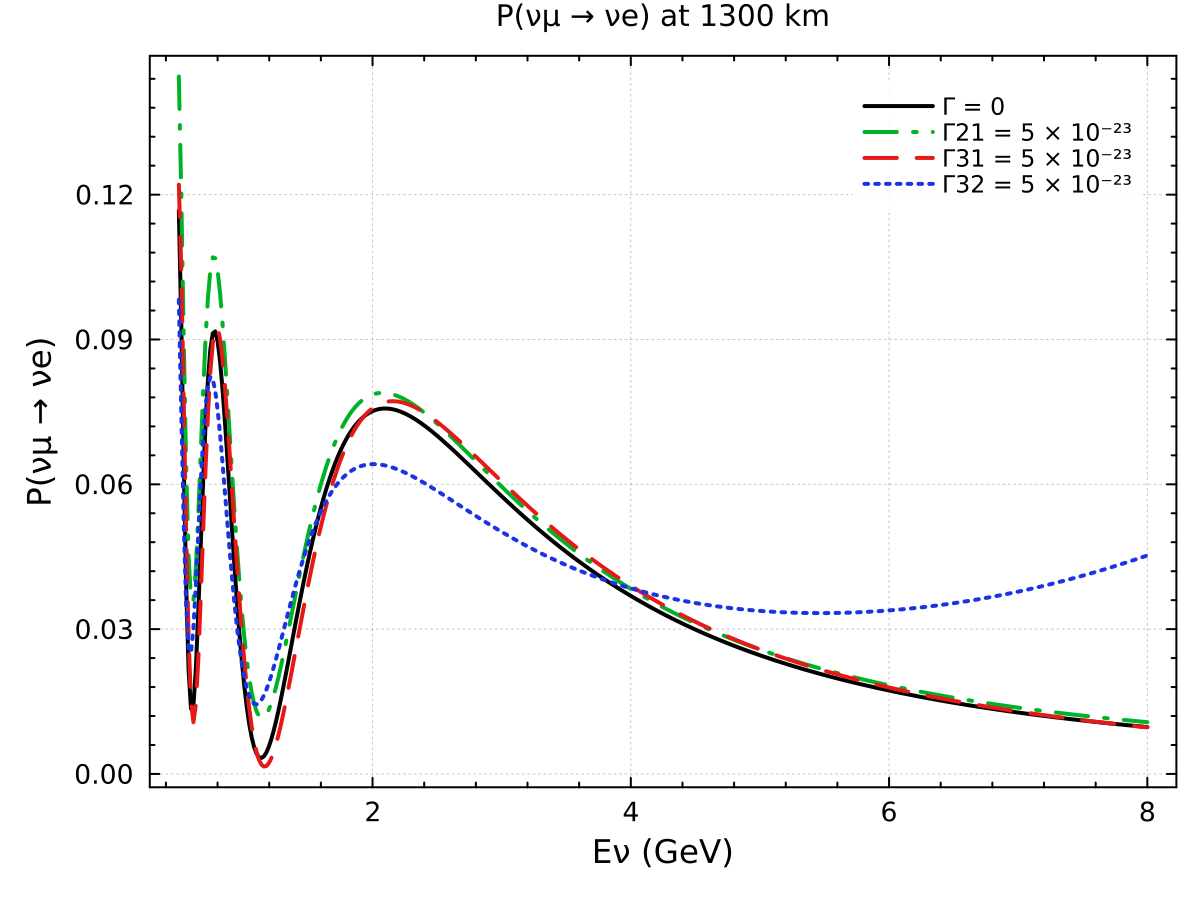

In [9]:
pairwise = NewPhysics(Decoherence(pairs = true))
use_model!(pairwise)
base = OscParams(pairwise, p)
plot_probability("Γ = 0" => base, "Γ21 = 5 × 10⁻²³" => OscParams(base; Γ21 = 5e-23), "Γ31 = 5 × 10⁻²³" => OscParams(base; Γ31 = 5e-23), "Γ32 = 5 × 10⁻²³" => OscParams(base; Γ32 = 5e-23); E, DUNE..., title = "P(νμ → νe) at 1300 km")

For neutrinos at DUNE, Γ32 does almost all the damping of the first oscillation maximum and pulls the high-energy tail up towards the average. Γ21 acts mostly at the second maximum below 1 GeV, and Γ31 hardly matters. A measurement with one Γ for all pairs is therefore mostly a measurement of Γ32.

## Together with scalar NSI, against the C engine

Blocks combine: `NewPhysics(ScalarNSI(:eμ, :eτ), Decoherence())` has the η's and Γ at once. The package tests this combination against the C engine of the scalar-NSI and decoherence study of DUNE (`snsi_engine_ihfix.c`) for three sets of parameters. The reference values ship with the package:

In [10]:
using NeutrinoScalarNSI
both = NewPhysics(ScalarNSI(:eμ, :eτ), Decoherence())
use_model!(both)
ref = [parse.(Float64, split(l)) for l in eachline(joinpath(pkgdir(NeutrinoDecoherence), "test", "snsi_c_reference.txt")) if !startswith(l, "#")]
c_base(config) = config < 3 ?
    OscParams(θ12 = asin(sqrt(0.3088)), θ13 = asin(sqrt(0.02249)), θ23 = asin(sqrt(0.470)), δ = deg2rad(207), Δm21 = 7.537e-5, Δm31 = 2.521e-3) :
    OscParams(θ12 = asin(sqrt(0.3088)), θ13 = asin(sqrt(0.02261)), θ23 = asin(sqrt(0.555)), δ = deg2rad(283), Δm21 = 7.537e-5, Δm31 = -2.5e-3 + 7.537e-5)
couplings = Dict(1 => (η_eτ = 0.1, Γ = 1e-23), 2 => (η_eμ = 0.05, δ_eμ = 1.0), 3 => (η_eτ = -0.05, δ_eτ = π / 3, Γ = 5e-24))
worst = maximum(ref) do (config, cp, Eν, pμe, pμμ)
    q = OscParams(both, c_base(Int(config)); couplings[Int(config)]...)
    max(abs(probability(q, :μ, :e; E = [Eν], DUNE..., antineutrino = cp < 0)[1] / pμe - 1),
        abs(probability(q, :μ, :μ; E = [Eν], DUNE..., antineutrino = cp < 0)[1] / pμμ - 1))
end   # the largest relative difference over 30 energies, ν and ν̄, both channels

2.744471316873387e-13

## How well DUNE constrains Γ

The DUNE configuration of the Technical Design Report, 5 years each of neutrino and antineutrino running. The data are simulated without decoherence. The fit over θ23, δ and Δm²31 takes about half a minute per point.

In [11]:
use_model!(model)
dune = Experiment(dune_configuration())   # the first time, this downloads the data tables from arXiv
running_time!(dune, 5.0)
for (label, x) in curves
    simulate!(x)
    println(rpad(label, 20), round.(Int, [sum(event_rates(dune; rule = r).signal) for r in 1:4]), "   (", join(rule_names(dune), ", "), ")")
end

Γ = 0               

[1591, 321, 15380, 8953]   (nue_app, nuebar_app, numu_dis, numubar_dis)
Γ = 10⁻²³ GeV       [1631, 336, 15604, 9020]   (nue_app, nuebar_app, numu_dis, numubar_dis)
Γ = 5 × 10⁻²³ GeV   [1766, 387, 16366, 9250]   (nue_app, nuebar_app, numu_dis, numubar_dis)


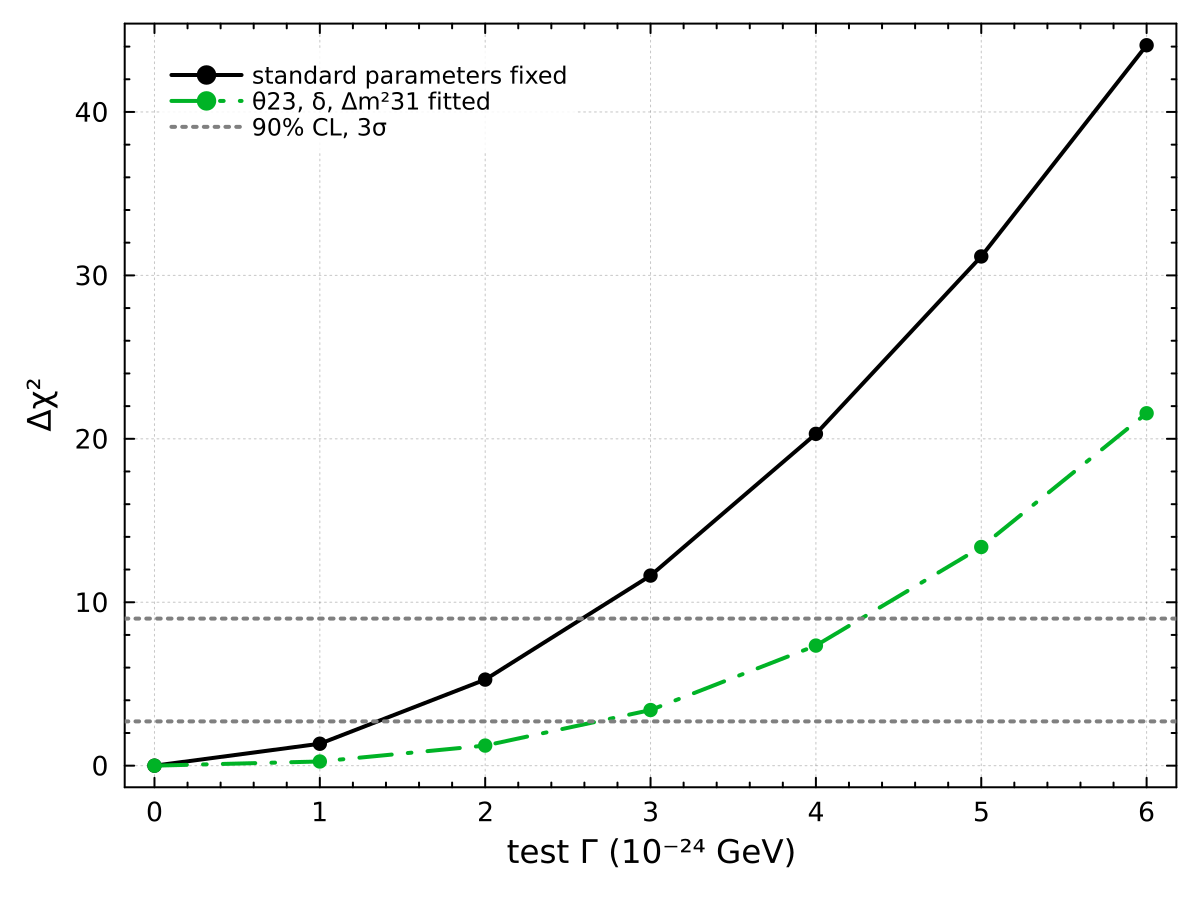

In [12]:
Γs = range(0, 6e-24, 7)
fixed = chi2_profile(sm, :Γ => Γs)
fitted = chi2_profile(sm, :Γ => Γs; free = (:θ23, :δ, :Δm31))
plot_curves(Γs ./ 1e-24, "standard parameters fixed" => fixed, "θ23, δ, Δm²31 fitted" => fitted; xlabel = "test Γ (10⁻²⁴ GeV)", ylabel = "Δχ²", markers = true)
hline!([2.71, 9]; color = :gray, linestyle = :dot, label = "90% CL, 3σ")

Γ is positive by construction, so the curve starts at Γ = 0. Where it crosses Δχ² = 2.71 gives DUNE's expected 90% CL upper limit for n = 0.

In [13]:
standard_engine!()   # back to standard three-flavour oscillations